Fuente: CEN_marzo.xlsx - CEN_marzo.csv (744 filas horarias)
Salidas:
CEN_marzo_datos_procesados_export.csv
numeralia_diaria_CEN_marzo2024.csv
resumen_CEN_marzo2024.txt
calendario_CEN_marzo2024.svg
grafica_numeralia_CEN_marzo2024.svg
distribucion_categorias_CEN_marzo2024.svg
Días por categoría: {'Aceptable': 16, 'Buena': 12, 'Mala': 3}
Dominancia: {'PM10': 15, 'PM2.5': 18, 'O3': 30, 'CO': 12, 'NO2': 0, 'SO2': 0}


,fecha,categoria_diaria,contaminantes_responsables,PM10_indicador_diario,PM2.5_indicador_diario,O3_indicador_diario,CO_indicador_diario,NO2_indicador_diario,SO2_indicador_diario
0,2024-03-01,Aceptable,O3,41.0,13.0,0.063,1.87,None,None
1,2024-03-02,Aceptable,O3,41.0,14.0,0.077,1.60,None,None
2,2024-03-03,Aceptable,O3,37.0,12.0,0.064,1.71,None,None
3,2024-03-04,Buena,PM10+PM2.5+O3+CO,28.0,7.0,0.057,1.22,None,None
4,2024-03-05,Aceptable,PM2.5+O3,43.0,16.0,0.073,1.95,None,None
5,2024-03-06,Aceptable,PM10+PM2.5+O3,48.0,16.0,0.075,2.40,None,None
6,2024-03-07,Buena,PM10+PM2.5+O3+CO,39.0,11.0,0.055,1.97,None,None
7,2024-03-08,Buena,PM10+PM2.5+O3+CO,41.0,11.0,0.057,2.09,None,None
8,2024-03-09,Aceptable,O3,43.0,13.0,0.088,1.84,None,None
9,2024-03-10,Mala,O3,46.0,17.0,0.098,2.11,None,None


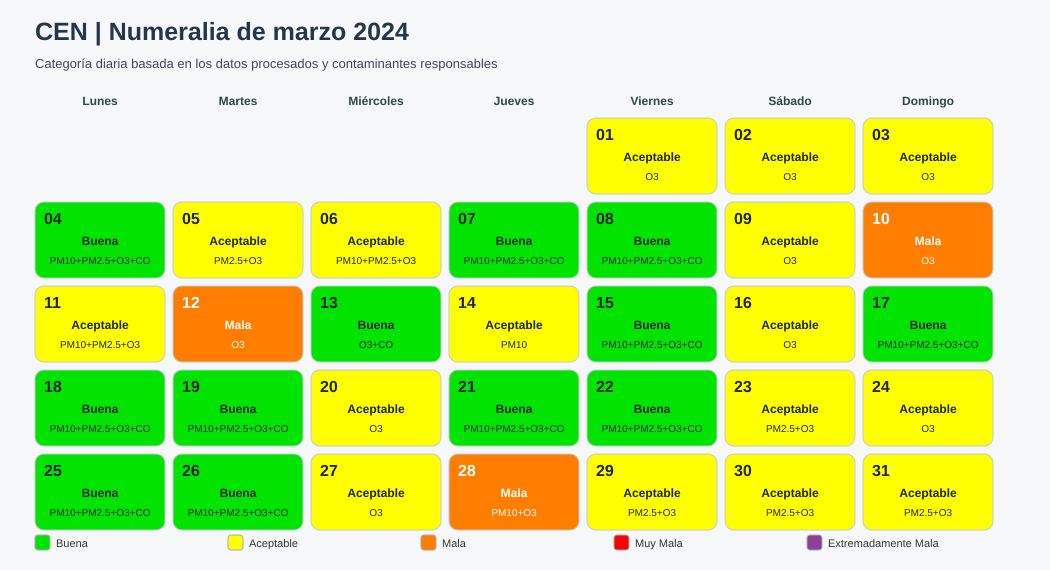

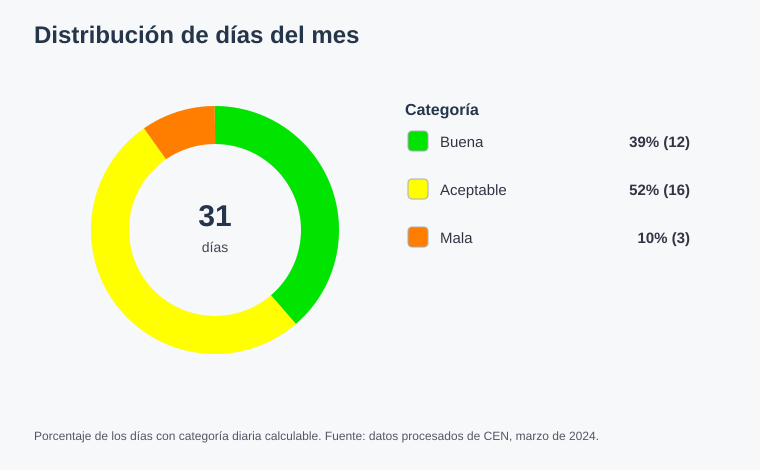

In [ ]:


from collections import Counter, defaultdict
from datetime import date, datetime
from pathlib import Path
import csv
import unicodedata
import xml.sax.saxutils as xml

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
INPUT_NAMES = ["CEN_marzo.xlsx - CEN_marzo.csv", "CEN_marzo.csv"]
YEAR, MONTH, N_DAYS = 2024, 3, 31
CATEGORIES = ["Buena", "Aceptable", "Mala", "Muy Mala", "Extremadamente Mala"]
RANK = {name: i for i, name in enumerate(CATEGORIES)}
COLORS = ["#00e400", "#ffff00", "#ff7e00", "#ff0000", "#8f3f97"]
POLLUTANTS = ["PM10", "PM2.5", "O3", "CO", "NO2", "SO2"]
# Cortes de categoría aplicables a marzo de 2024 según la NOM-172-SEMARNAT-2023.
BREAKS = {
    "PM10": [45, 60, 132, 213], "PM2.5": [15, 33, 79, 130],
    "O3": [.058, .090, .135, .175], "CO": [5.00, 9.00, 12.00, 16.00],
    "NO2": [.053, .106, .160, .213], "SO2": [.035, .075, .185, .304],
}
METRICS = {
    "PM10": ("PM10", "promedio diario 24 h (µg/m³)"),
    "PM2.5": ("PM2.5", "promedio diario 24 h (µg/m³)"),
    "O3": ("O3", "máximo horario diario (ppm)"),
    "CO": ("CO_prom_8h", "máximo promedio móvil 8 h (ppm)"),
    "NO2": ("NO2", "máximo horario diario (ppm)"),
    "SO2": ("SO2", "máximo horario diario (ppm)"),
}


def find_input():
    for name in INPUT_NAMES:
        p = BASE / name
        if p.exists():
            return p
    candidates = sorted(p for p in BASE.glob("*CEN*marzo*.csv") if "export" not in p.name.lower())
    if candidates:
        return candidates[0]
    raise FileNotFoundError("No encuentro 'CEN_marzo.xlsx - CEN_marzo.csv' junto al script.")


def unique_headers(headers):
    seen, out = Counter(), []
    for value in headers:
        name = value.strip()
        seen[name] += 1
        out.append(name if seen[name] == 1 else f"{name}_{seen[name]}")
    return out


def norm(value):
    value = unicodedata.normalize("NFD", str(value or "").strip().lower())
    return "".join(c for c in value if unicodedata.category(c) != "Mn")


def category(value):
    key = norm(value).replace("\n", " ").strip()
    key = " ".join(key.split())
    for cat in CATEGORIES:
        if norm(cat) == key:
            return cat
    return None


def round_base(pollutant, value):
    if value is None: return None
    if pollutant in ("PM10", "PM2.5"):
        return int(value + .5)
    places = 2 if pollutant == "CO" else 3
    scale = 10 ** places
    return int(value * scale + .5) / scale


def category_for(pollutant, value):
    value = round_base(pollutant, value)
    if value is None or value < 0: return None
    for i, limit in enumerate(BREAKS[pollutant]):
        if value <= limit:
            return CATEGORIES[i]
    return CATEGORIES[-1]


def number(value):
    if value is None:
        return None
    s = str(value).strip()
    if not s or norm(s) in {"na", "nan", "nd", "none"}:
        return None
    # La fuente CSV guarda los decimales con coma y los cita, p. ej. "0,025".
    if "," in s and "." not in s:
        s = s.replace(",", ".")
    try:
        return float(s)
    except ValueError:
        return None


def read_source():
    source = find_input()
    with source.open("r", newline="", encoding="utf-8-sig") as f:
        reader = csv.reader(f)
        original_headers = next(reader)
        headers = unique_headers(original_headers)
        required = {"DATE", "HOUR", "PM10", "PM2.5", "O3", "CO_prom_8h"}
        if not required.issubset(headers):
            raise ValueError(f"Faltan columnas requeridas en {source.name}: {sorted(required-set(headers))}")
        records = []
        for row in reader:
            if not row:
                continue
            row += [""] * (len(headers) - len(row))
            rec = dict(zip(headers, row))
            try:
                dt = datetime.fromisoformat(rec["DATE"].strip())
            except (TypeError, ValueError):
                continue
            if dt.year != YEAR or dt.month != MONTH:
                continue
            records.append((dt, rec))
    records.sort(key=lambda x: x[0])
    if not records:
        raise ValueError("El archivo no contiene registros de marzo de 2024.")
    return source, headers, records


def summarize(records, headers):
    by_day = defaultdict(list)
    for dt, row in records:
        by_day[dt.day].append((dt, row))
    out = []
    for day in range(1, N_DAYS + 1):
        day_rows = by_day.get(day, [])
        rec = {
            "fecha": f"{YEAR}-{MONTH:02d}-{day:02d}",
            "horas_en_archivo": len(day_rows),
        }
        categories = {}
        for pol, (metric_col, _) in METRICS.items():
            metric_vals = [number(row.get(metric_col)) for _, row in day_rows]
            metric_vals = [v for v in metric_vals if v is not None and v >= 0]
            # Las partículas se promedian durante 24 h; gases usan máximo horario o móvil de 8 h.
            minimum = 18
            if len(metric_vals) < minimum:
                indicator = None
            elif pol in ("PM10", "PM2.5"):
                indicator = sum(metric_vals) / len(metric_vals)
            else:
                indicator = max(metric_vals)
            indicator = round_base(pol, indicator)
            cat = category_for(pol, indicator) if indicator is not None else None
            categories[pol] = cat
            rec[f"{pol}_n_valores_validos"] = len(metric_vals)
            rec[f"{pol}_indicador_diario"] = indicator
            rec[f"{pol}_categoria_diaria"] = cat or "ND"
        valid = [(p, c) for p, c in categories.items() if c]
        daily_category = max((c for _, c in valid), key=RANK.get) if valid else None
        daily_rank = RANK.get(daily_category, -1)
        responsible = [p for p, c in valid if RANK[c] == daily_rank] if daily_category else []
        rec["categoria_diaria"] = daily_category or "ND"
        rec["contaminantes_responsables"] = "+".join(p for p in POLLUTANTS if p in responsible) or "ND"
        out.append(rec)
    return out


def export_hourly_csv(source, headers, records):
    path = BASE / "CEN_marzo_datos_procesados_export.csv"
    def write(target):
        with target.open("w", newline="", encoding="utf-8-sig") as f:
            w = csv.writer(f)
            w.writerow(headers)
            w.writerows([row.get(h, "") for h in headers] for _, row in records)
    try:
        write(path)
    except PermissionError:
        path = BASE / "CEN_marzo_datos_procesados_export_actualizado.csv"
        write(path)
    return path


def export_daily_csv(rows):
    path = BASE / "numeralia_diaria_CEN_marzo2024.csv"
    def write(target):
        with target.open("w", newline="", encoding="utf-8-sig") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0]))
            w.writeheader()
            w.writerows(rows)
    try:
        write(path)
    except PermissionError:
        path = BASE / "numeralia_diaria_CEN_marzo2024_actualizado.csv"
        write(path)
    return path


def write_summary(rows, source_name):
    valid_days = [r for r in rows if r["categoria_diaria"] != "ND"]
    cats = Counter(r["categoria_diaria"] for r in valid_days)
    dom = Counter(p for r in valid_days for p in r["contaminantes_responsables"].split("+") if p in POLLUTANTS)
    worst_rank = max((RANK[r["categoria_diaria"]] for r in valid_days), default=-1)
    worst_days = [r["fecha"] for r in valid_days if worst_rank >= 0 and RANK[r["categoria_diaria"]] == worst_rank]
    lines = [
        f"Numeralia diaria | Estación CEN | Marzo {YEAR}",
        f"Fuente procesada: {source_name}",
        f"Total de días: {N_DAYS}; días con categoría global: {len(valid_days)}; días ND: {N_DAYS-len(valid_days)}.",
        "Días por categoría: " + ", ".join(f"{c}: {cats.get(c, 0)}" for c in CATEGORIES),
        "Días como contaminante responsable (empates cuentan para cada uno): " + ", ".join(f"{p}: {dom.get(p, 0)}" for p in POLLUTANTS),
        f"Categoría más desfavorable: {CATEGORIES[worst_rank] if worst_rank >= 0 else 'ND'}; " + (", ".join(worst_days) if worst_days else "sin días calculables"),
        "Categoría y responsable por día: " + "; ".join(f"{r['fecha'][-2:]}: {r['categoria_diaria']} ({r['contaminantes_responsables']})" for r in rows),
        "Método de resumen: promedio diario 24 h para PM10/PM2.5; máximo horario para O3/NO2/SO2; máximo de CO_prom_8h para CO. La categoría diaria es la peor entre los indicadores calculables.",
        "PM10 y PM2.5 requieren al menos 18 mediciones horarias; O3/NO2/SO2 y CO requieren al menos 18 valores del indicador diario usado por este análisis.",
        "Las columnas Categoria_Global y Categoria_* horarias de la fuente no se usan para esta agregación; sirven para una lectura de la evolución horaria.",
        "NA/ND en un contaminante indica que la hoja no proporcionó una categoría/medición válida.",
    ]
    path = BASE / "resumen_CEN_marzo2024.txt"
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


def write_calendar(rows):
    width, height, left, top, cw, ch, gap = 1050, 570, 35, 118, 130, 76, 8
    offset = date(YEAR, MONTH, 1).weekday()
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
             '<rect width="100%" height="100%" fill="#f7f8fa"/>',
             '<text x="35" y="40" font-family="Arial" font-size="25" font-weight="700" fill="#25364a">CEN | Numeralia de marzo 2024</text>',
             '<text x="35" y="68" font-family="Arial" font-size="13" fill="#445">Categoría diaria basada en los datos procesados y contaminantes responsables</text>']
    weekdays = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
    for col, name in enumerate(weekdays):
        x = left + col * (cw + gap)
        parts.append(f'<text x="{x+cw/2}" y="{top-13}" text-anchor="middle" font-family="Arial" font-size="12" font-weight="700" fill="#344">{name}</text>')
    for r in rows:
        d = int(r["fecha"][-2:]); pos = offset+d-1; col, wr = pos % 7, pos // 7
        x, y = left+col*(cw+gap), top+wr*(ch+gap)
        cat = r["categoria_diaria"]
        color = COLORS[RANK[cat]] if cat in RANK else "#d5d9df"
        text_color = "#20242a" if cat in ("Buena", "Aceptable") else "#ffffff"
        resp = r["contaminantes_responsables"]
        parts += [f'<rect x="{x}" y="{y}" width="{cw}" height="{ch}" rx="9" fill="{color}" stroke="#c3c9d1"/>',
                  f'<text x="{x+9}" y="{y+22}" font-family="Arial" font-size="16" font-weight="700" fill="{text_color}">{d:02}</text>',
                  f'<text x="{x+cw/2}" y="{y+43}" text-anchor="middle" font-family="Arial" font-size="12" font-weight="700" fill="{text_color}">{xml.escape(cat)}</text>',
                  f'<text x="{x+cw/2}" y="{y+62}" text-anchor="middle" font-family="Arial" font-size="10" fill="{text_color}">{xml.escape(resp)}</text>']
    # Leyenda al pie.
    for i, cat in enumerate(CATEGORIES):
        x = 35+i*193
        parts += [f'<rect x="{x}" y="535" width="15" height="15" rx="3" fill="{COLORS[i]}" stroke="#aaa"/>',
                  f'<text x="{x+21}" y="547" font-family="Arial" font-size="11" fill="#333">{cat}</text>']
    parts.append('</svg>')
    path = BASE / "calendario_CEN_marzo2024.svg"
    path.write_text("\n".join(parts), encoding="utf-8")
    return path


def write_graph(rows):
    cats = Counter(r["categoria_diaria"] for r in rows if r["categoria_diaria"] in RANK)
    dom = Counter(p for r in rows for p in r["contaminantes_responsables"].split("+") if p in POLLUTANTS)
    labels = {"O3":"O₃", "CO":"CO", "PM10":"PM10", "PM2.5":"PM2.5", "NO2":"NO₂", "SO2":"SO₂"}
    width, height, left, barmax = 920, 600, 245, 570
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
             '<rect width="100%" height="100%" fill="#fff"/>',
             '<text x="35" y="40" font-family="Arial" font-size="23" font-weight="700" fill="#25364a">CEN | Resumen de numeralia | Marzo 2024</text>',
             '<text x="35" y="72" font-family="Arial" font-size="16" font-weight="700" fill="#25364a">Días por categoría</text>']
    maxc = max(cats.values(), default=1)
    for i, c in enumerate(CATEGORIES):
        n = cats.get(c, 0); y = 92+i*33; bar = n/maxc*barmax if maxc else 0
        parts += [f'<text x="{left-12}" y="{y+17}" text-anchor="end" font-family="Arial" font-size="13" fill="#334">{c}</text>',
                  f'<rect x="{left}" y="{y}" width="{bar:.1f}" height="21" rx="3" fill="{COLORS[i]}" stroke="#aaa"/>',
                  f'<text x="{left+bar+8:.1f}" y="{y+16}" font-family="Arial" font-size="12" font-weight="700" fill="#334">{n}</text>']
    parts.append('<text x="35" y="292" font-family="Arial" font-size="16" font-weight="700" fill="#25364a">Días como contaminante responsable*</text>')
    maxd = max((dom.get(p, 0) for p in POLLUTANTS), default=1) or 1
    for i, p in enumerate(POLLUTANTS):
        n = dom.get(p, 0); y = 313+i*32; bar = n/maxd*barmax
        parts += [f'<text x="{left-12}" y="{y+17}" text-anchor="end" font-family="Arial" font-size="13" fill="#334">{labels[p]}</text>',
                  f'<rect x="{left}" y="{y}" width="{bar:.1f}" height="21" rx="3" fill="#34495e"/>',
                  f'<text x="{left+bar+8:.1f}" y="{y+16}" font-family="Arial" font-size="12" font-weight="700" fill="#334">{n}</text>']
    parts += ['<text x="35" y="570" font-family="Arial" font-size="11" fill="#555">*Los empates de categoría global cuentan para cada contaminante responsable; los conteos pueden sumar más de 31.</text>', '</svg>']
    path = BASE / "grafica_numeralia_CEN_marzo2024.svg"
    path.write_text("\n".join(parts), encoding="utf-8")
    return path


def write_donut(rows):
    """Gráfica de dona para distribución porcentual de días por categoría."""
    counts = Counter(r["categoria_diaria"] for r in rows if r["categoria_diaria"] in RANK)
    present = [(cat, counts.get(cat, 0), COLORS[i]) for i, cat in enumerate(CATEGORIES) if counts.get(cat, 0)]
    total = sum(n for _, n, _ in present)
    cx, cy, radius, stroke = 215, 230, 105, 38
    circumference = 2 * 3.141592653589793 * radius
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="760" height="470" viewBox="0 0 760 470">',
             '<rect width="100%" height="100%" fill="#f7f8fa"/>',
             '<text x="34" y="43" font-family="Arial" font-size="24" font-weight="700" fill="#25364a">Distribución de días del mes</text>',
             f'<circle cx="{cx}" cy="{cy}" r="{radius}" fill="none" stroke="#e5e7eb" stroke-width="{stroke}"/>']
    offset = 0.0
    for cat, n, color in present:
        length = circumference * n / total if total else 0
        parts.append(f'<circle cx="{cx}" cy="{cy}" r="{radius}" fill="none" stroke="{color}" stroke-width="{stroke}" stroke-dasharray="{length:.3f} {circumference-length:.3f}" stroke-dashoffset="{-offset:.3f}" transform="rotate(-90 {cx} {cy})"><title>{cat}: {n} días ({100*n/total:.1f}%)</title></circle>')
        offset += length
    parts += [f'<text x="{cx}" y="{cy-4}" text-anchor="middle" font-family="Arial" font-size="30" font-weight="700" fill="#25364a">{total}</text>',
              f'<text x="{cx}" y="{cy+22}" text-anchor="middle" font-family="Arial" font-size="14" fill="#445">días</text>',
              '<text x="405" y="115" font-family="Arial" font-size="16" font-weight="700" fill="#25364a">Categoría</text>']
    for i, (cat, n, color) in enumerate(present):
        y = 145 + i*48
        pct = 100*n/total if total else 0
        parts += [f'<rect x="408" y="{y-14}" width="20" height="20" rx="4" fill="{color}" stroke="#aab"/>',
                  f'<text x="440" y="{y+2}" font-family="Arial" font-size="15" fill="#334">{cat}</text>',
                  f'<text x="690" y="{y+2}" text-anchor="end" font-family="Arial" font-size="15" font-weight="700" fill="#334">{pct:.0f}% ({n})</text>']
    parts.append('<text x="34" y="440" font-family="Arial" font-size="12" fill="#556">Porcentaje de los días con categoría diaria calculable. Fuente: datos procesados de CEN, marzo de 2024.</text>')
    parts.append('</svg>')
    path = BASE / "distribucion_categorias_CEN_marzo2024.svg"
    path.write_text("\n".join(parts), encoding="utf-8")
    return path


def display_in_notebook(rows, summary_path, calendar_path, donut_path):
    """Muestra resultados en línea si se ejecutó desde Jupyter/Google Colab."""
    try:
        shell = get_ipython()  # definido por IPython; no existe al ejecutar desde terminal
    except NameError:
        return
    if shell is None:
        return
    try:
        from IPython.display import HTML, SVG, display
        summary = xml.escape(summary_path.read_text(encoding="utf-8"))
        display(HTML(f'<pre style="white-space:pre-wrap">{summary}</pre>'))
        # Mostrar las variables principales para revisar cada día sin abrir el CSV.
        try:
            import pandas as pd
            view_cols = ["fecha", "categoria_diaria", "contaminantes_responsables"]
            view_cols += [f"{p}_indicador_diario" for p in POLLUTANTS]
            display(pd.DataFrame(rows)[view_cols])
        except ImportError:
            pass
        display(SVG(filename=str(calendar_path)))
        display(SVG(filename=str(donut_path)))
    except Exception as exc:
        print(f"Los archivos se guardaron, pero no se pudieron mostrar en línea: {exc}")


def main():
    source, headers, records = read_source()
    daily = summarize(records, headers)
    outputs = [export_hourly_csv(source, headers, records), export_daily_csv(daily),
               write_summary(daily, source.name), write_calendar(daily), write_graph(daily), write_donut(daily)]
    hourly_export = export_hourly_csv(source, headers, records)
    daily_export = export_daily_csv(daily)
    summary_path = write_summary(daily, source.name)
    calendar_path = write_calendar(daily)
    graph_path = write_graph(daily)
    donut_path = write_donut(daily)
    outputs = [hourly_export, daily_export, summary_path, calendar_path, graph_path, donut_path]
    print(f"Fuente: {source.name} ({len(records)} filas horarias)")
    print("Salidas:")
    for path in outputs:
        if path is not None: print(path.name)
    print("Días por categoría:", dict(Counter(r["categoria_diaria"] for r in daily)))
    print("Dominancia:", {p: sum(p in r["contaminantes_responsables"].split("+") for r in daily) for p in POLLUTANTS})
    display_in_notebook(daily, summary_path, calendar_path, donut_path)


if __name__ == "__main__":
    main()

In [ ]:
with open(BASE / 'resumen_CEN_marzo2024.txt', 'r', encoding='utf-8') as f:
    summary_content = f.read()
print(summary_content)